In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np


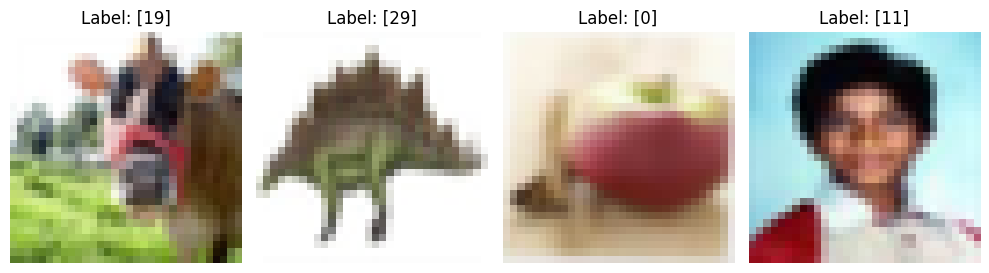

In [2]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) =  keras.datasets.cifar100.load_data()

# Print 4 images in a row
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
num_classes = 100
input_shape = (32, 32,3)
batch_size = 128
epochs = 100

In [4]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (50000, 32, 32, 3, 1)
50000 train samples
10000 test samples


In [5]:
from keras import layers

In [6]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3),activation="relu")(inputs)
x=layers.BatchNormalization()(x)
x=layers.ReLU()(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model=keras.Model(inputs,outputs)

In [7]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 30, 30, 32)        896       
                                                                 
 batch_normalization (BatchN  (None, 30, 30, 32)       128       
 ormalization)                                                   
                                                                 
 re_lu (ReLU)                (None, 30, 30, 32)        0         
                                                                 
 flatten (Flatten)           (None, 28800)             0         
                                                                 
 dense (Dense)               (None, 100)               2880100   
                                                             

In [8]:
model.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history=model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 6s 8ms/step - loss: 4.2573 - accuracy: 0.0683 - val_loss: 4.2190 - val_accuracy: 0.1090
Epoch 2/100
352/352 [==============================] - 3s 8ms/step - loss: 3.8036 - accuracy: 0.1423 - val_loss: 3.7995 - val_accuracy: 0.1500
Epoch 3/100
352/352 [==============================] - 3s 8ms/step - loss: 3.5717 - accuracy: 0.1875 - val_loss: 3.6526 - val_accuracy: 0.1706
Epoch 4/100
352/352 [==============================] - 3s 8ms/step - loss: 3.3882 - accuracy: 0.2226 - val_loss: 3.5494 - val_accuracy: 0.1876
Epoch 5/100
352/352 [==============================] - 3s 7ms/step - loss: 3.2321 - accuracy: 0.2542 - val_loss: 3.4706 - val_accuracy: 0.2050
Epoch 6/100
352/352 [==============================] - 3s 8ms/step - loss: 3.1004 - accuracy: 0.2819 - val_loss: 3.4014 - val_accuracy: 0.2170
Epoch 7/100
352/352 [==============================] - 3s 8ms/step - loss: 2.9845 - accuracy: 0.3057 - val_loss: 3.3503 - val_accuracy: 0.2276

Epoch 58/100
352/352 [==============================] - 3s 8ms/step - loss: 0.9157 - accuracy: 0.8395 - val_loss: 3.2677 - val_accuracy: 0.2968
Epoch 59/100
352/352 [==============================] - 3s 8ms/step - loss: 0.8949 - accuracy: 0.8452 - val_loss: 3.2773 - val_accuracy: 0.2958
Epoch 60/100
352/352 [==============================] - 3s 8ms/step - loss: 0.8744 - accuracy: 0.8508 - val_loss: 3.2874 - val_accuracy: 0.2984
Epoch 61/100
352/352 [==============================] - 3s 7ms/step - loss: 0.8540 - accuracy: 0.8570 - val_loss: 3.2905 - val_accuracy: 0.2976
Epoch 62/100
352/352 [==============================] - 3s 7ms/step - loss: 0.8335 - accuracy: 0.8630 - val_loss: 3.3104 - val_accuracy: 0.2948
Epoch 63/100
352/352 [==============================] - 3s 8ms/step - loss: 0.8133 - accuracy: 0.8667 - val_loss: 3.3170 - val_accuracy: 0.2946
Epoch 64/100
352/352 [==============================] - 3s 8ms/step - loss: 0.7941 - accuracy: 0.8718 - val_loss: 3.3300 - val_accuracy:

In [9]:
class Weibull(keras.layers.Layer):
    def __init__(self, shape, scale, **kwargs):
        super().__init__(**kwargs)
        self.shape = shape
        self.scale = scale

    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)
        
        # Avoid division by zero or negative scale
        z = tf.math.maximum(inputs / self.scale, 0.0)

        # Weibull CDF: 1 - exp(-(z)^shape)
        weibull_cdf = 1.0 - tf.exp(-tf.pow(z, self.shape))

        # Optional: hard-zero for negative inputs (domain of Weibull CDF is x ≥ 0)
        output = tf.where(inputs < 0, 0.0, weibull_cdf)

        return output

    def get_config(self):
        config = super().get_config()
        config.update({
            "shape": self.shape,
            "scale": self.scale,
        })
        return config


In [10]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=Weibull(shape=1,scale=5)(x)#2,5
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_ray=keras.Model(inputs,outputs)

In [11]:
model_ray.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 30, 30, 32)        896       
                                                                 
 batch_normalization_1 (Batc  (None, 30, 30, 32)       128       
 hNormalization)                                                 
                                                                 
 weibull (Weibull)           (None, 30, 30, 32)        0         
                                                                 
 flatten_1 (Flatten)         (None, 28800)             0         
                                                                 
 dense_1 (Dense)             (None, 100)               2880100   
                                                           

In [12]:
model_ray.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_ray=model_ray.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 5s 13ms/step - loss: 4.3375 - accuracy: 0.0704 - val_loss: 4.3296 - val_accuracy: 0.0996
Epoch 2/100
352/352 [==============================] - 4s 12ms/step - loss: 4.0331 - accuracy: 0.1190 - val_loss: 3.9878 - val_accuracy: 0.1282
Epoch 3/100
352/352 [==============================] - 4s 12ms/step - loss: 3.8818 - accuracy: 0.1423 - val_loss: 3.8691 - val_accuracy: 0.1454
Epoch 4/100
352/352 [==============================] - 4s 12ms/step - loss: 3.7822 - accuracy: 0.1605 - val_loss: 3.7961 - val_accuracy: 0.1584
Epoch 5/100
352/352 [==============================] - 4s 12ms/step - loss: 3.7055 - accuracy: 0.1741 - val_loss: 3.7379 - val_accuracy: 0.1660
Epoch 6/100
352/352 [==============================] - 4s 12ms/step - loss: 3.6438 - accuracy: 0.1848 - val_loss: 3.6912 - val_accuracy: 0.1774
Epoch 7/100
352/352 [==============================] - 4s 12ms/step - loss: 3.5917 - accuracy: 0.1945 - val_loss: 3.6534 - val_accuracy:

352/352 [==============================] - 4s 12ms/step - loss: 2.6368 - accuracy: 0.3932 - val_loss: 3.1037 - val_accuracy: 0.2664
Epoch 58/100
352/352 [==============================] - 5s 13ms/step - loss: 2.6273 - accuracy: 0.3949 - val_loss: 3.0982 - val_accuracy: 0.2718
Epoch 59/100
352/352 [==============================] - 5s 13ms/step - loss: 2.6145 - accuracy: 0.3983 - val_loss: 3.0955 - val_accuracy: 0.2732
Epoch 60/100
352/352 [==============================] - 4s 12ms/step - loss: 2.6034 - accuracy: 0.4006 - val_loss: 3.0921 - val_accuracy: 0.2696
Epoch 61/100
352/352 [==============================] - 4s 12ms/step - loss: 2.5933 - accuracy: 0.4023 - val_loss: 3.0866 - val_accuracy: 0.2726
Epoch 62/100
352/352 [==============================] - 4s 12ms/step - loss: 2.5811 - accuracy: 0.4064 - val_loss: 3.0831 - val_accuracy: 0.2746
Epoch 63/100
352/352 [==============================] - 4s 12ms/step - loss: 2.5707 - accuracy: 0.4092 - val_loss: 3.0783 - val_accuracy: 0.274

the value of breast cancer

| Metric   | Weibull CDF Activation | ReLU                |
| -------- | ---------------------- | ------------------- |
| RMSE     | 0.0337                 | 0.03                |
| MAE      | 0.0231                 | 0.03                |
| MAPE     | 14.22%                 | 15.73%              |

In [13]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=tf.keras.activations.gelu(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_gelu=keras.Model(inputs,outputs)

In [14]:
model_gelu.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_gelu=model_gelu.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 5s 12ms/step - loss: 4.1317 - accuracy: 0.0887 - val_loss: 4.0821 - val_accuracy: 0.1186
Epoch 2/100
352/352 [==============================] - 4s 11ms/step - loss: 3.6824 - accuracy: 0.1626 - val_loss: 3.6929 - val_accuracy: 0.1618
Epoch 3/100
352/352 [==============================] - 4s 11ms/step - loss: 3.4918 - accuracy: 0.1993 - val_loss: 3.5807 - val_accuracy: 0.1830
Epoch 4/100
352/352 [==============================] - 4s 11ms/step - loss: 3.3555 - accuracy: 0.2253 - val_loss: 3.5018 - val_accuracy: 0.1990
Epoch 5/100
352/352 [==============================] - 4s 11ms/step - loss: 3.2459 - accuracy: 0.2481 - val_loss: 3.4452 - val_accuracy: 0.2096
Epoch 6/100
352/352 [==============================] - 4s 11ms/step - loss: 3.1507 - accuracy: 0.2690 - val_loss: 3.3989 - val_accuracy: 0.2180
Epoch 7/100
352/352 [==============================] - 4s 11ms/step - loss: 3.0654 - accuracy: 0.2865 - val_loss: 3.3609 - val_accuracy:

352/352 [==============================] - 4s 11ms/step - loss: 1.3147 - accuracy: 0.7272 - val_loss: 3.1882 - val_accuracy: 0.2834
Epoch 58/100
352/352 [==============================] - 4s 11ms/step - loss: 1.2931 - accuracy: 0.7335 - val_loss: 3.1909 - val_accuracy: 0.2880
Epoch 59/100
352/352 [==============================] - 4s 11ms/step - loss: 1.2735 - accuracy: 0.7391 - val_loss: 3.1998 - val_accuracy: 0.2838
Epoch 60/100
352/352 [==============================] - 4s 11ms/step - loss: 1.2546 - accuracy: 0.7428 - val_loss: 3.2064 - val_accuracy: 0.2828
Epoch 61/100
352/352 [==============================] - 4s 11ms/step - loss: 1.2360 - accuracy: 0.7493 - val_loss: 3.2099 - val_accuracy: 0.2860
Epoch 62/100
352/352 [==============================] - 4s 11ms/step - loss: 1.2162 - accuracy: 0.7557 - val_loss: 3.2183 - val_accuracy: 0.2840
Epoch 63/100
352/352 [==============================] - 4s 11ms/step - loss: 1.1977 - accuracy: 0.7598 - val_loss: 3.2227 - val_accuracy: 0.284

In [37]:
def plot_loss_comparison(relu_history, custom_history1,custom_history2):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 1.5
    y_max = 4.5
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('A')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('B')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim( -10, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('C')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()



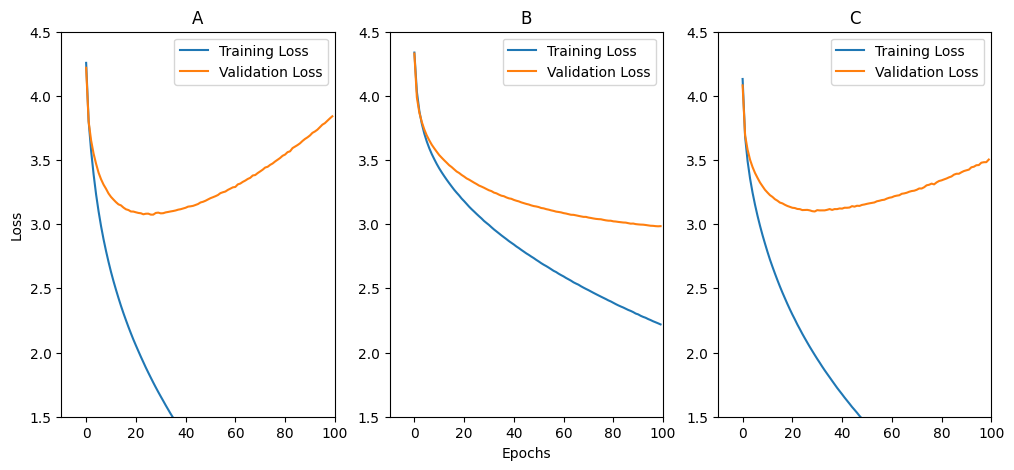

<Figure size 640x480 with 0 Axes>

In [38]:
# Usage
plot_loss_comparison(history,history_ray,history_gelu)

In [24]:
score_relu = model.evaluate(x_test, y_test, verbose=0)
score_weilu = model_ray.evaluate(x_test, y_test, verbose=0)
score_gelu = model_gelu.evaluate(x_test, y_test, verbose=0)


In [39]:
print("RELU:", score_relu)
print("WeiLU:", score_weilu)
print("GELU:", score_gelu)

RELU: [3.7842040061950684, 0.28119999170303345]
WeiLU: [2.958117961883545, 0.30230000615119934]
GELU: [3.478447198867798, 0.28200000524520874]
